In [2]:
import os
for dirname, _, filenames in os.walk("/kaggle/input"):
    print(dirname, len(filenames))
    break
print(os.listdir("/kaggle/input"))

/kaggle/input 0
['competitions']


In [3]:
import os

DATA = "/kaggle/input/competitions/ai-of-god-5/participant_data"
print(os.listdir(DATA))

['sample_submission.csv', 'train_images', 'train.csv', 'data_description.md', 'test_images']


In [4]:
import pandas as pd 
from PIL import Image 

train = pd.read_csv(f"{DATA}/train.csv")
test_files = os.listdir(f"{DATA}/test_images")

print(train.shape)
print(train.head())
print("Test images:", len(test_files))

(3087, 2)
                               image_id animal_class
0          000dc07b2b676f5d0ec0acf9.png     reindeer
1  0063d33c0996495e9337062ad3f13319.png     antelope
2          007227c159bdba58d63406ca.png        sheep
3  00838ab89a624affb0b36cd676d511c4.png          bee
4          0099c1e57da598c85cef9c22.png        snake
Test images: 1179


In [5]:
widths = []
heights = []
modes =[]
#class balance checking 
counts = train["animal_class"].value_counts()
print(counts.head(5))
print(counts.tail(5))
print("min:", counts.min(), "max:",counts.max())

#widths,heights,modes = [],[],[]
for name in train["image_id"]:
    img = Image.open(f"{DATA}/train_images/{name}")
    widths.append(img.width)
    heights.append(img.height)
    modes.append(img.mode)

train["w"] = widths
train["h"] = heights
train["aspect"] = train["w"]/train["h"]

print(set(modes))
print(train[["w","h","aspect"]].describe())


animal_class
hedgehog        51
grasshopper     51
hare            51
hippopotamus    51
hyena           51
Name: count, dtype: int64
animal_class
starfish          41
seal              41
pelecaniformes    41
raccoon           34
jellyfish         23
Name: count, dtype: int64
min: 23 max: 51
{'RGB'}
                 w            h       aspect
count  3087.000000  3087.000000  3087.000000
mean    824.515387   578.611273     1.495233
std     762.785628   563.452774     0.375361
min     145.000000   120.000000     0.415820
25%     275.000000   183.000000     1.333333
50%     496.000000   350.000000     1.501587
75%    1200.000000   768.000000     1.777778
max    4854.000000  4064.000000     3.500000


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

X = train[["w", "h", "aspect"]]
y = train["animal_class"]

score = cross_val_score(RandomForestClassifier(n_estimators=200), X, y, cv=5).mean()
print("Accuracy from size alone:", score)
print("Random guessing would give:", 1 / 72)

Accuracy from size alone: 0.016522687815035693
Random guessing would give: 0.013888888888888888


In [7]:
import numpy as np

def count_colors(path):
    arr = np.array(Image.open(path).convert("RGB"))
    return len(np.unique(arr.reshape(-1, 3), axis=0))

sample = train.sample(200, random_state=0)
sample_colors = [count_colors(f"{DATA}/train_images/{n}") for n in sample["image_id"]]

print(pd.Series(sample_colors).describe())

count      200.000000
mean      2934.115000
std       3098.903098
min        174.000000
25%        836.250000
50%       1903.000000
75%       3883.500000
max      18792.000000
dtype: float64


In [14]:
#Every file has a "fingerprint" (an MD5 hash). Two identical files give the same fingerprint.
#So I am computing one fingerprint per image and look for repeats.
# def file_hash(path):
#    with open(path, "rb") as f:
#         return hashlib.md5(f.read()).hexdigest()

# print(file_hash(path))   # should match Piece 1
# train_hashes = []
# for name in train["image_id"]:
#     train_hashes.append(file_hash(f"{DATA}/train_images/{name}"))

# train["hash"] = train_hashes
# test_hashes = set()
# for name in test_files:
#     test_hashes.add(file_hash(f"{DATA}/test_images/{name}"))
# print("Duplicates inside train:", train["hash"].duplicated().sum())
# print("Train images also in test:", train["hash"].isin(test_hashes).sum())
#Output
#03254adfd8b5e99d31beb9080b2816d2
#<function file_hash at 0x7b2a710c3100>
#Duplicates inside train: 0
#Train images also in test: 0

In [16]:
import timm
model = timm.create_model("vit_base_patch14_dinov2.lvd142m",
                          pretrained=True, num_classes=0, img_size=224)
model = model.eval().cuda()

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

In [18]:
config = timm.data.resolve_data_config({}, model=model)
config["input_size"] = (3,224,224)
transform = timm.data.create_transform(**config)
print(config)

img = Image.open(f"{DATA}/train_images/{train['image_id'][0]}").convert("RGB")
x = transform(img).unsqueeze(0).cuda()     # add a batch dimension

with torch.no_grad():
    feat = model(x)

print(x.shape, feat.shape)

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 1.0, 'crop_mode': 'center'}
torch.Size([1, 3, 224, 224]) torch.Size([1, 768])


In [26]:
def pad_to_square(img):
    w, h = img.size
    side = max(w, h)
    canvas = Image.new("RGB", (side, side), (128, 128, 128))
    canvas.paste(img, ((side - w) // 2, (side - h) // 2))
    return canvas
from torchvision import transforms as T

transform = T.Compose([
    T.Lambda(pad_to_square),
    T.Resize((224, 224), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=config["mean"], std=config["std"]),
])
from torch.utils.data import Dataset, DataLoader

class ImgData(Dataset):
    def __init__(self, folder, names):
        self.folder = folder
        self.names = list(names)
    def __len__(self):
        return len(self.names)
    def __getitem__(self, i):
        img = Image.open(f"{self.folder}/{self.names[i]}").convert("RGB")
        return transform(img)

train_loader = DataLoader(ImgData(f"{DATA}/train_images", train["image_id"]),
                          batch_size=64, num_workers=4)

In [27]:
import numpy as np

def extract(loader):
    out = []
    for batch in loader:
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            f = model(batch.cuda())
        out.append(f.float().cpu().numpy())
    return np.concatenate(out)

train_feats = extract(train_loader)
print(train_feats.shape)    # expect (3087, 768)
np.save("dino_b224_train.npy", train_feats)

(3087, 768)


In [31]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

y = train["animal_class"].values
X = train_feats

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

In [32]:
scores = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
    scaler = StandardScaler().fit(X[tr_idx])
    clf = LogisticRegression(max_iter=2000, C=1.0)
    clf.fit(scaler.transform(X[tr_idx]), y[tr_idx])
    pred = clf.predict(scaler.transform(X[va_idx]))
    f1 = f1_score(y[va_idx], pred, average="macro")
    scores.append(f1)
    print(fold, round(f1, 4))

print("Mean macro F1:", np.mean(scores))

0 0.9163
1 0.9033
2 0.906
3 0.9212
4 0.9086
Mean macro F1: 0.911079296520473


In [36]:
sub = pd.read_csv(f"{DATA}/sample_submission.csv")
print(sub.shape)
test_loader = DataLoader(ImgData(f"{DATA}/test_images",sub["image_id"]),
                        batch_size=64,num_workers = 4,shuffle=False)
test_feats = extract(test_loader)
print(test_feats.shape)               # expect (1179, 768)
np.save("dino_b224_test.npy", test_feats)


(1179, 2)
(1179, 768)


In [37]:
scaler = StandardScaler().fit(train_feats)

clf = LogisticRegression(max_iter=2000, C=1.0)
clf.fit(scaler.transform(train_feats), y)

pred = clf.predict(scaler.transform(test_feats))
print("Predictions:", len(pred))      # expect 1179

Predictions: 1179


In [38]:
submission = pd.DataFrame({
    "image_id": sub["image_id"],
    "animal_class": pred
})
submission.to_csv("submission.csv", index=False)

print(submission.head())
print("submission.csv created!")

                               image_id animal_class
0          6eab26f8b156fda90e1bc819.png   woodpecker
1  483f71af1c174ab2a0c31a836267227d.png     antelope
2  563878772a3f47ce98cf9c10039a0219.png   chimpanzee
3  9aa782974228482390c1a237408a967a.png      hamster
4  3ed553219cf049b8bd9a65c300b02fb0.png          cat
submission.csv created!


In [39]:
chk = pd.read_csv("submission.csv")
print(chk.shape, list(chk.columns))                                   # (1179, 2) ['image_id', 'animal_class']
print("IDs unique:", chk["image_id"].is_unique)                       # True
print("Labels valid:", chk["animal_class"].isin(train["animal_class"].unique()).all())   # True
print("Classes predicted:", chk["animal_class"].nunique())            # close to 72
print(chk["animal_class"].value_counts().head())                      # no single class dominating

(1179, 2) ['image_id', 'animal_class']
IDs unique: True
Labels valid: True
Classes predicted: 72
animal_class
wombat        26
duck          23
rat           23
sparrow       22
woodpecker    21
Name: count, dtype: int64


In [40]:
chk = pd.read_csv("submission.csv")
print(chk.shape, list(chk.columns))                                   # (1179, 2) ['image_id', 'animal_class']
print("IDs unique:", chk["image_id"].is_unique)                       # True
print("Labels valid:", chk["animal_class"].isin(train["animal_class"].unique()).all())   # True
print("Classes predicted:", chk["animal_class"].nunique())            # close to 72
print(chk["animal_class"].value_counts().head())                      # no single class dominating

(1179, 2) ['image_id', 'animal_class']
IDs unique: True
Labels valid: True
Classes predicted: 72
animal_class
wombat        26
duck          23
rat           23
sparrow       22
woodpecker    21
Name: count, dtype: int64


In [41]:
import shutil
shutil.copy("submission.csv", "sub_dino_b224_lr.csv")

'sub_dino_b224_lr.csv'

In [42]:
chk_loader = DataLoader(ImgData(f"{DATA}/train_images", train["image_id"][:64]),
                        batch_size=64, num_workers=2)
re = extract(chk_loader)
print(re.shape, np.abs(re - train_feats[:64]).max())

(64, 768) 0.0


In [43]:
from sklearn.preprocessing import normalize

a = normalize(train_feats)
b = normalize(test_feats)

s = a @ a.T
np.fill_diagonal(s, -1)
nn = s.argmax(1)

print("train -> nearest train: sim", s.max(1).mean(), "| same label:", (y[nn] == y).mean())
print("test  -> nearest train: sim", (b @ a.T).max(1).mean())

train -> nearest train: sim 0.73936546 | same label: 0.86977648202138
test  -> nearest train: sim 0.7286182


In [44]:
chk = pd.read_csv("submission.csv")
print((chk["image_id"].values == sub["image_id"].values).all())
print("agree with my logreg preds:", (chk["animal_class"].values == pred).mean())

True
agree with my logreg preds: 1.0


In [45]:
# confidence on test
p_test = clf.predict_proba(scaler.transform(test_feats)).max(1)

# confidence on validation images (out-of-fold, like real unseen data)
conf_val = []
for tr_idx, va_idx in skf.split(X, y):
    sc = StandardScaler().fit(X[tr_idx])
    c = LogisticRegression(max_iter=2000).fit(sc.transform(X[tr_idx]), y[tr_idx])
    conf_val.append(c.predict_proba(sc.transform(X[va_idx])).max(1))
conf_val = np.concatenate(conf_val)

print("val confidence :", conf_val.mean())
print("test confidence:", p_test.mean())

val confidence : 0.908367705305322
test confidence: 0.9030149493166373


In [46]:
from sklearn.preprocessing import normalize
a = normalize(train_feats)
b = normalize(test_feats)

s = a @ a.T
np.fill_diagonal(s, -1)
tr_nn = s.max(1)
te_nn = (b @ a.T).max(1)

for t in [0.8, 0.85, 0.9, 0.95]:
    print(t, "train:", (tr_nn > t).mean().round(3), "| test:", (te_nn > t).mean().round(3))

0.8 train: 0.328 | test: 0.293
0.85 train: 0.204 | test: 0.158
0.9 train: 0.108 | test: 0.083
0.95 train: 0.031 | test: 0.029


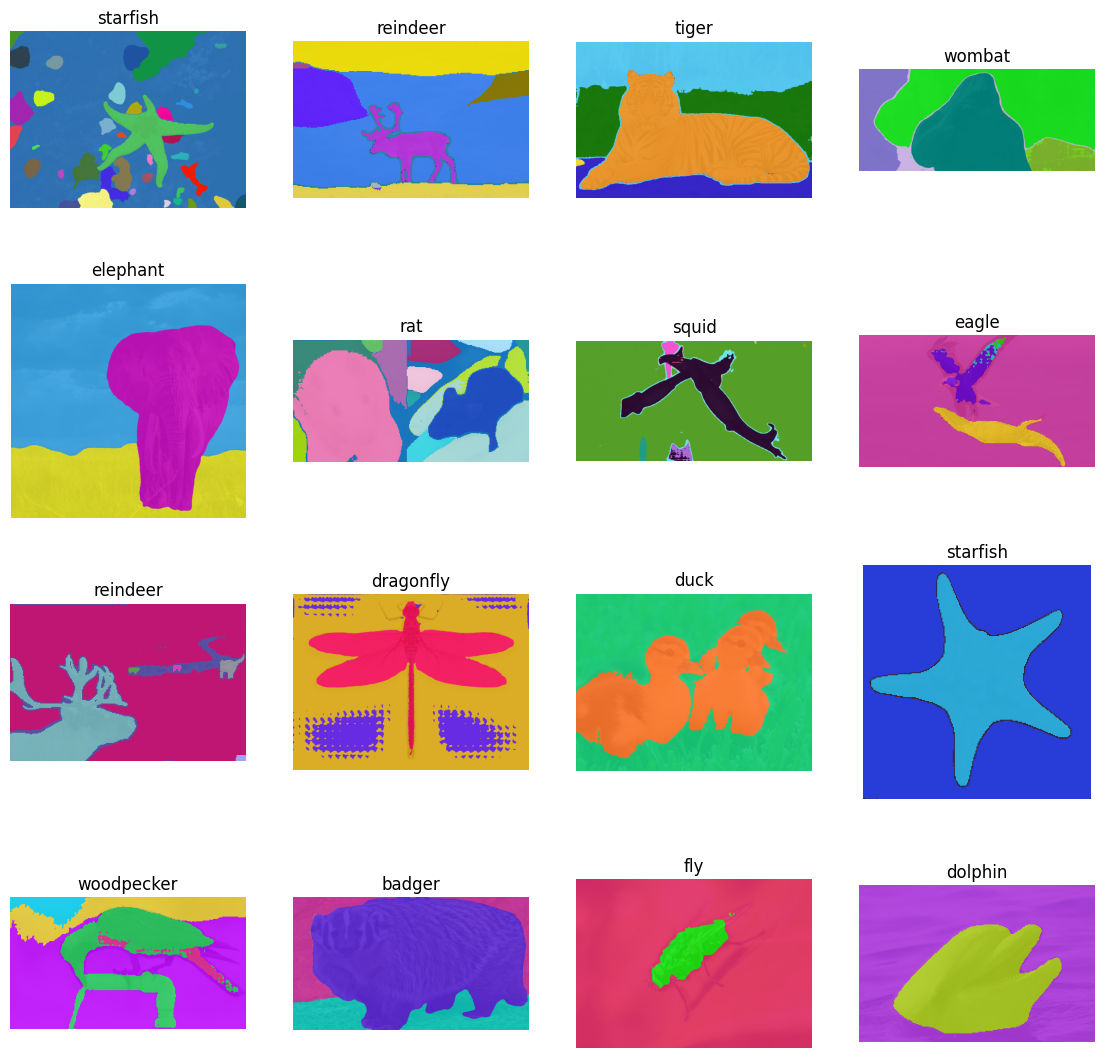

In [47]:
import matplotlib.pyplot as plt
pred_map = submission.set_index("image_id")["animal_class"]

picks = sub.sample(16, random_state=1)
plt.figure(figsize=(14, 14))
for i, (_, r) in enumerate(picks.iterrows()):
    plt.subplot(4, 4, i + 1)
    plt.imshow(Image.open(f"{DATA}/test_images/{r['image_id']}"))
    plt.title(pred_map[r["image_id"]])
    plt.axis("off")
plt.show()

In [48]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

Xa = np.vstack([train_feats, test_feats])
ya = np.r_[np.zeros(len(train_feats)), np.ones(len(test_feats))]

p = cross_val_predict(LogisticRegression(max_iter=2000, C=0.1),
                      StandardScaler().fit_transform(Xa), ya,
                      cv=5, method="predict_proba")[:, 1]
print("AUC:", roc_auc_score(ya, p))

AUC: 0.4902794915777208


In [49]:
def count_colors(path):
    arr = np.array(Image.open(path).convert("RGB"))
    return len(np.unique(arr.reshape(-1, 3), axis=0))

s = sub.sample(200, random_state=0)
tc = [count_colors(f"{DATA}/test_images/{n}") for n in s["image_id"]]
print(pd.Series(tc).describe())

count      200.000000
mean      2664.685000
std       3315.067044
min        114.000000
25%        727.000000
50%       1406.500000
75%       2906.000000
max      18752.000000
dtype: float64


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import normalize

a = normalize(train_feats)
for thr in [0.2, 0.3, 0.4]:
    g = AgglomerativeClustering(n_clusters=None, distance_threshold=thr,
                                metric="cosine", linkage="average").fit_predict(a)
    sc_list = []
    for tr_idx, va_idx in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, g):
        sc = StandardScaler().fit(X[tr_idx])
        c = LogisticRegression(max_iter=2000).fit(sc.transform(X[tr_idx]), y[tr_idx])
        sc_list.append(f1_score(y[va_idx], c.predict(sc.transform(X[va_idx])), average="macro"))
    print(thr, "groups:", len(set(g)), "F1:", round(np.mean(sc_list), 3))